# Comparing Solutions to Spam Email Detections

- Author: Jovan Heng Ghim Hong

**Goal:** To the fastest and smallest model that cna achieve a high accuracy in detecting spam emails.

**How is comparison done?**

- We evaluate the following metrics
  - Recall (Spm Detection Rate)
  - Model Size
  - Training Time
  - Inference Time

- Note that all models are trained and evaluated on the same dataset for a fair comparison.

## BoW and TF-IDF Implementation for Spam Email Detection

I want to try to build a simple spam email detector. For now I will try to implement BoW and TF-IDF as a more lightweight alternative to word embeddings.

Since BoW and TF-IDF remove word order, a simple MLP should be sufficient, removing the need for a order based RNN like LSTM or GRU.

In [154]:
#imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import DataLoader, TensorDataset, Subset

torch.manual_seed(42)
np.random.seed(42)

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, recall_score

from nltk.tokenize import word_tokenize

from src.eda import clean_text, remove_stopwords, lemmatize_reviews
from src.utils import timer

In [155]:
# import the dataset
data = pd.read_csv('dataset/email.csv')
X = data['Message'].values
y = [0 if l == 'ham' else 1 for l in data['Category'].values]

X_train , X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [156]:
# here we clean the text and prepare it for vectorization
X_train = [remove_stopwords(clean_text(text)) for text in X_train]
X_test = [remove_stopwords(clean_text(text)) for text in X_test]

# for a simple model like BoW or TF-IDF lemmatization typically helps
X_train_lematized = [lemmatize_reviews(text) for text in X_train]
X_test_lematized = [lemmatize_reviews(text) for text in X_test]

### Binary Bag of Words

In [157]:
# we will still try to implement on a lemmatized dataset with both BoW and TF-IDF
bow_vectorizer = CountVectorizer(tokenizer=word_tokenize, binary=True, lowercase=True, max_features=5000, ngram_range=(1,2))
X_sequences = bow_vectorizer.fit_transform(X_train)
X_test_sequences = bow_vectorizer.transform(X_test)

X_lemmatized_sequences = bow_vectorizer.fit_transform(X_train_lematized)
X_test_lemmatized_sequences = bow_vectorizer.transform(X_test_lematized)

In [158]:
## Prepare DataLoaders
## Original
binary_bow_x_train = TensorDataset(torch.tensor(X_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
binary_bow_x_test = TensorDataset(torch.tensor(X_test_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

binary_bow_x_train_loader = DataLoader(binary_bow_x_train, batch_size=32, shuffle=True)
binary_bow_x_test_loader = DataLoader(binary_bow_x_test, batch_size=32)

## lematized
binary_bow_lematized_x_train = TensorDataset(torch.tensor(X_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
binary_bow_lematized_x_test = TensorDataset(torch.tensor(X_test_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

binary_bow_lematized_x_train_loader = DataLoader(binary_bow_lematized_x_train, batch_size=32, shuffle=True)
binary_bow_lematized_x_test_loader = DataLoader(binary_bow_lematized_x_test, batch_size=32)

In [159]:
# we build a simple sequential model as baseline
class BaselineLinearModel(nn.Module):
  def __init__(self, input_dim, hidden_dim, output_dim):
    super(BaselineLinearModel, self).__init__()
    self.fc1 = nn.Linear(input_dim, hidden_dim)
    self.relu = nn.ReLU()
    self.fc2 = nn.Linear(hidden_dim, output_dim)
  
  def forward(self, x):
    out = self.fc1(x)
    out = self.relu(out)
    out = self.fc2(out)
    return out

  def fit(self, epochs, train_loader, loss_fn, optimizer, kf=None):
    super().train()

    if kf is not None:
      pass

    for i in range(epochs):
      epoch_loss = 0.0
      total = 0 
      correct = 0 

      for x_batch, y_batch in train_loader:
        # reset gradients
        optimizer.zero_grad()

        logits = self(x_batch)

        # back propagation
        loss = loss_fn(logits, y_batch)
        loss.backward()
        
        # update weights
        optimizer.step()
        
        # store weights
        epoch_loss += loss.item()
        
        # compute accuracy
        predictions = logits.argmax(dim=1)
      
        total += y_batch.size(0)
        correct += (predictions == y_batch).sum().item()

      epoch_accuracy = correct / total * 100
      print(f"Epoch {i+1}/{epochs}, Loss: {epoch_loss/len(binary_bow_x_train_loader):.4f}, Accuracy: {epoch_accuracy:.2f}%")
     
     
  def eval(self, test_loader):
    super().eval()
    predictions = []

    with torch.no_grad():
      for x_batch, _ in test_loader:
        logits = self(x_batch)
        preds = logits.argmax(dim=1)
        predictions.extend(preds.tolist())

    return predictions


baseline_model = BaselineLinearModel(X_sequences.shape[1], 4, 2)
lemmatized_baseline_model = BaselineLinearModel(X_lemmatized_sequences.shape[1], 4, 2)

loss_fn = nn.CrossEntropyLoss()
optimizer = Adam(baseline_model.parameters(), lr=1e-03)
lemmatized_optimizer = Adam(lemmatized_baseline_model.parameters(), lr=1e-03)

In [160]:
print('Training Baseline BoW Model')
with timer('Baseline BoW Model Training Time'):
  baseline_model.fit(5, binary_bow_x_train_loader, loss_fn, optimizer)

print()
print('Training Baseline Lemmatized BoW Model')
with timer('Baseline Lemmatized BoW Model Training Time'):
  lemmatized_baseline_model.fit(5, binary_bow_lematized_x_train_loader, loss_fn, lemmatized_optimizer)

Training Baseline BoW Model
Epoch 1/5, Loss: 0.6508, Accuracy: 56.80%
Epoch 2/5, Loss: 0.3098, Accuracy: 97.73%
Epoch 3/5, Loss: 0.1544, Accuracy: 98.14%
Epoch 4/5, Loss: 0.0967, Accuracy: 98.52%
Epoch 5/5, Loss: 0.0688, Accuracy: 98.86%
Baseline BoW Model Training Time: 2.9372s

Training Baseline Lemmatized BoW Model
Epoch 1/5, Loss: 0.5226, Accuracy: 92.73%
Epoch 2/5, Loss: 0.2780, Accuracy: 97.94%
Epoch 3/5, Loss: 0.1556, Accuracy: 98.47%
Epoch 4/5, Loss: 0.1008, Accuracy: 98.79%
Epoch 5/5, Loss: 0.0720, Accuracy: 99.04%
Baseline Lemmatized BoW Model Training Time: 3.0057s


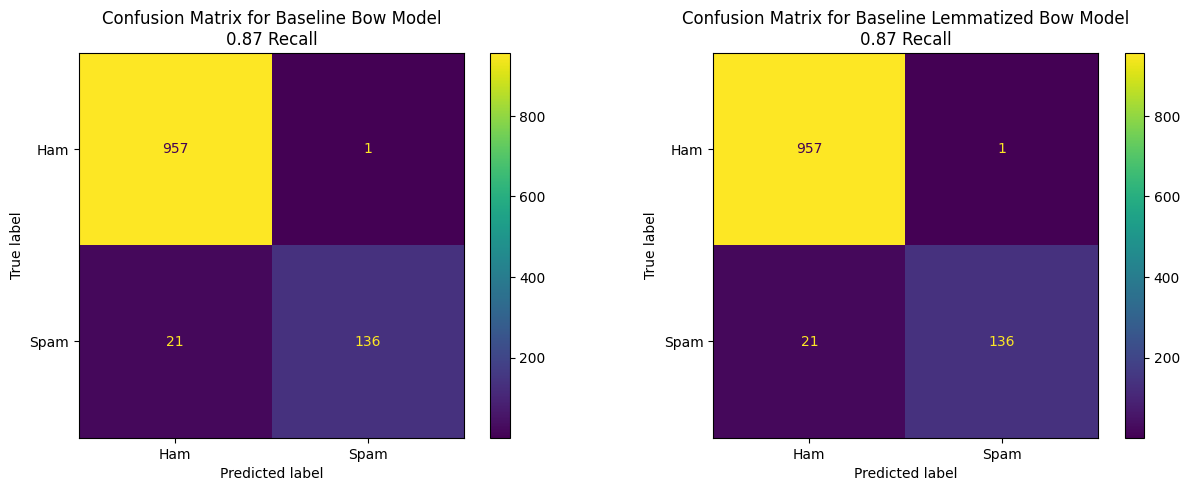

In [161]:
# get predictions
baseline_bow_predictions = baseline_model.eval(binary_bow_x_test_loader)
baseline_bow_lematized_predictions = lemmatized_baseline_model.eval(binary_bow_lematized_x_test_loader)

# plot cms
fig , axes = plt.subplots(1, 2, figsize=(15, 5))

# non lemmatized
baseline_bow_cm = confusion_matrix(y_test, baseline_bow_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=baseline_bow_cm, display_labels=['Ham', 'Spam'])
disp.plot(ax=axes[0])
axes[0].set_title(f'Confusion Matrix for Baseline Bow Model\n{recall_score(y_test, baseline_bow_predictions, pos_label=1):.2f} Recall')

# lemmatized
baseline_bow_lematized_cm = confusion_matrix(y_test, baseline_bow_lematized_predictions)
disp_lematized = ConfusionMatrixDisplay(confusion_matrix=baseline_bow_lematized_cm, display_labels=['Ham', 'Spam'])
disp_lematized.plot(ax=axes[1])
axes[1].set_title(f'Confusion Matrix for Baseline Lemmatized Bow Model\n{recall_score(y_test, baseline_bow_lematized_predictions, pos_label=1):.2f} Recall')

plt.show()

Here we see that such a simple model such as Binary BoW with a simple MLP can achieve a high recall on the spam emails.

The results here also show that lemmatization has small improvements on the model performance for BoW


--- 

### TF-IDF

In theory since TF-IDF takes into account word importance, it should perform better than BoW. 

In [162]:
tf_idf_vectorizer = TfidfVectorizer(tokenizer=word_tokenize, lowercase=True, max_features=5000, ngram_range=(1,2))
X_sequences = tf_idf_vectorizer.fit_transform(X_train)
X_test_sequences = tf_idf_vectorizer.transform(X_test)

X_lemmatized_sequences = tf_idf_vectorizer.fit_transform(X_train_lematized)
X_test_lemmatized_sequences = tf_idf_vectorizer.transform(X_test_lematized)

In [163]:
## Prepare DataLoaders
## Original
tf_idf_x_train = TensorDataset(torch.tensor(X_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
tf_idf_x_test = TensorDataset(torch.tensor(X_test_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

tf_idf_x_train_loader = DataLoader(tf_idf_x_train, batch_size=32, shuffle=True)
tf_idf_x_test_loader = DataLoader(tf_idf_x_test, batch_size=32)

## lematized
tf_idf_lematized_x_train = TensorDataset(torch.tensor(X_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
tf_idf_lematized_x_test = TensorDataset(torch.tensor(X_test_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

tf_idf_lematized_x_train_loader = DataLoader(tf_idf_lematized_x_train, batch_size=32, shuffle=True)
tf_idf_lematized_x_test_loader = DataLoader(tf_idf_lematized_x_test, batch_size=32)

In [164]:
# we reuse the model defined earlier for consistency

tf_idf_baseline_model = BaselineLinearModel(X_sequences.shape[1], 4, 2)
tf_idf_lemmatized_baseline_model = BaselineLinearModel(X_lemmatized_sequences.shape[1], 4, 2)

loss_fn = nn.CrossEntropyLoss()
optimizer = Adam(tf_idf_baseline_model.parameters(), lr=1e-03)
lemmatized_optimizer = Adam(tf_idf_lemmatized_baseline_model.parameters(), lr=1e-03)

In [165]:
print('Training Baseline TF-IDF Model')
with timer('Baseline TF-IDF Model Training Time'):
  tf_idf_baseline_model.fit(5, tf_idf_x_train_loader, loss_fn, optimizer)

print()
print('Training Baseline Lemmatized TF-IDF Model')
with timer('Baseline Lemmatized TF-IDF Model Training Time'):
  tf_idf_lemmatized_baseline_model.fit(5, tf_idf_lematized_x_train_loader, loss_fn, lemmatized_optimizer)

Training Baseline TF-IDF Model
Epoch 1/5, Loss: 0.7302, Accuracy: 39.41%
Epoch 2/5, Loss: 0.4581, Accuracy: 91.18%
Epoch 3/5, Loss: 0.2688, Accuracy: 94.06%
Epoch 4/5, Loss: 0.1666, Accuracy: 96.61%
Epoch 5/5, Loss: 0.1135, Accuracy: 97.94%
Baseline TF-IDF Model Training Time: 2.6951s

Training Baseline Lemmatized TF-IDF Model
Epoch 1/5, Loss: 0.5813, Accuracy: 86.74%
Epoch 2/5, Loss: 0.4081, Accuracy: 88.34%
Epoch 3/5, Loss: 0.2720, Accuracy: 93.88%
Epoch 4/5, Loss: 0.1822, Accuracy: 96.57%
Epoch 5/5, Loss: 0.1287, Accuracy: 97.87%
Baseline Lemmatized TF-IDF Model Training Time: 2.2142s


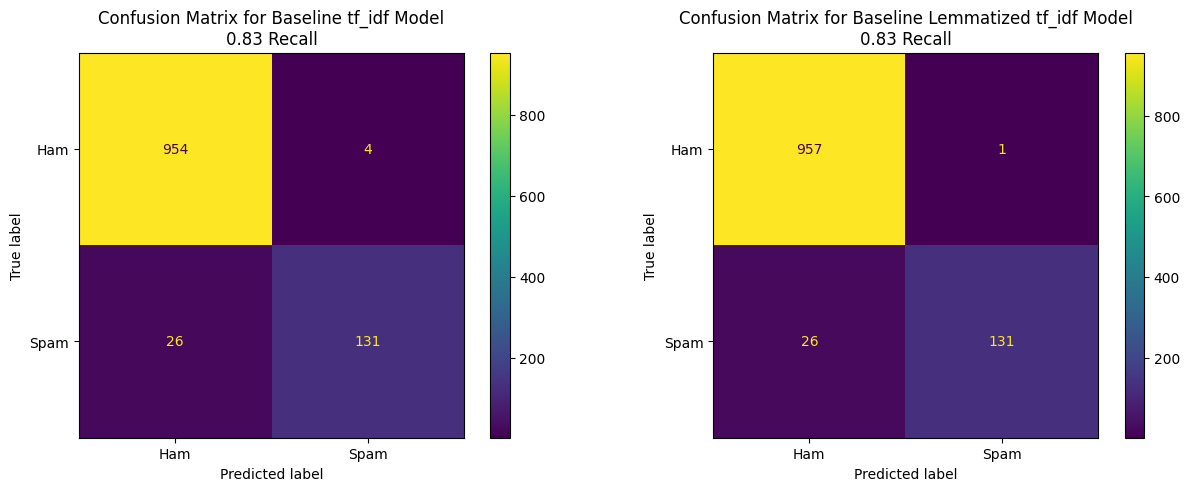

In [166]:
# get predictions
baseline_tf_idf_predictions = tf_idf_baseline_model.eval(tf_idf_x_test_loader)
baseline_tf_idf_lematized_predictions = tf_idf_lemmatized_baseline_model.eval(tf_idf_lematized_x_test_loader)

# plot cms
fig , axes = plt.subplots(1, 2, figsize=(15, 5))

# non lemmatized
baseline_tf_idf_cm = confusion_matrix(y_test, baseline_tf_idf_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=baseline_tf_idf_cm, display_labels=['Ham', 'Spam'])
disp.plot(ax=axes[0])
axes[0].set_title(f'Confusion Matrix for Baseline tf_idf Model\n{recall_score(y_test, baseline_tf_idf_predictions, pos_label=1):.2f} Recall')

# lemmatized
baseline_tf_idf_lematized_cm = confusion_matrix(y_test, baseline_tf_idf_lematized_predictions)
disp_lematized = ConfusionMatrixDisplay(confusion_matrix=baseline_tf_idf_lematized_cm, display_labels=['Ham', 'Spam'])
disp_lematized.plot(ax=axes[1])
axes[1].set_title(f'Confusion Matrix for Baseline Lemmatized tf_idf Model\n{recall_score(y_test, baseline_tf_idf_lematized_predictions, pos_label=1):.2f} Recall')

plt.show()